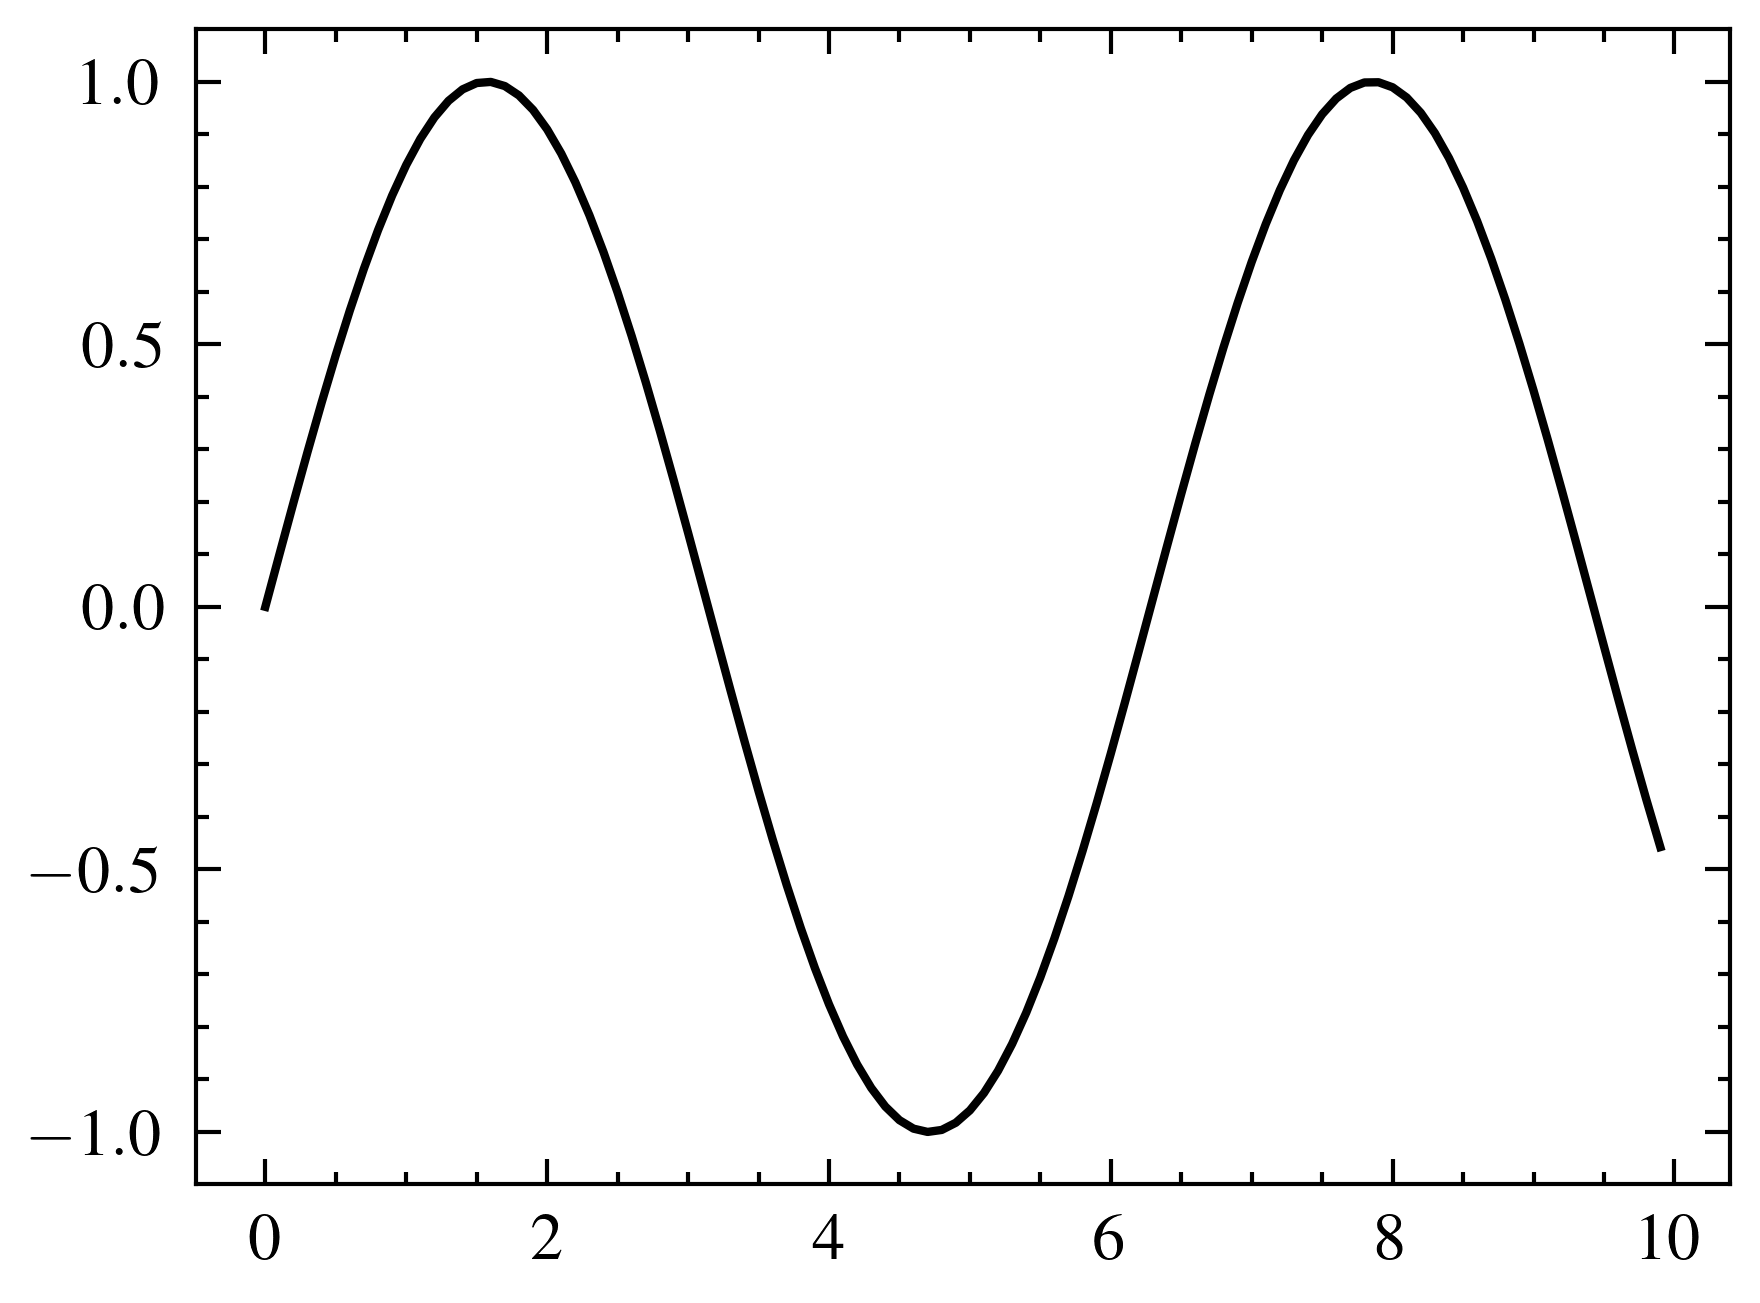

In [9]:
import matplotlib.pyplot as plt
import scienceplots
import numpy as np 
import pandas as pd
import os 

x = np.arange(0, 10, 0.1)
y = np.sin(x)

with plt.style.context(['science', 'ieee']):
    plt.figure()
    plt.plot(x, y)
    plt.show()

# Intensity reconstruction

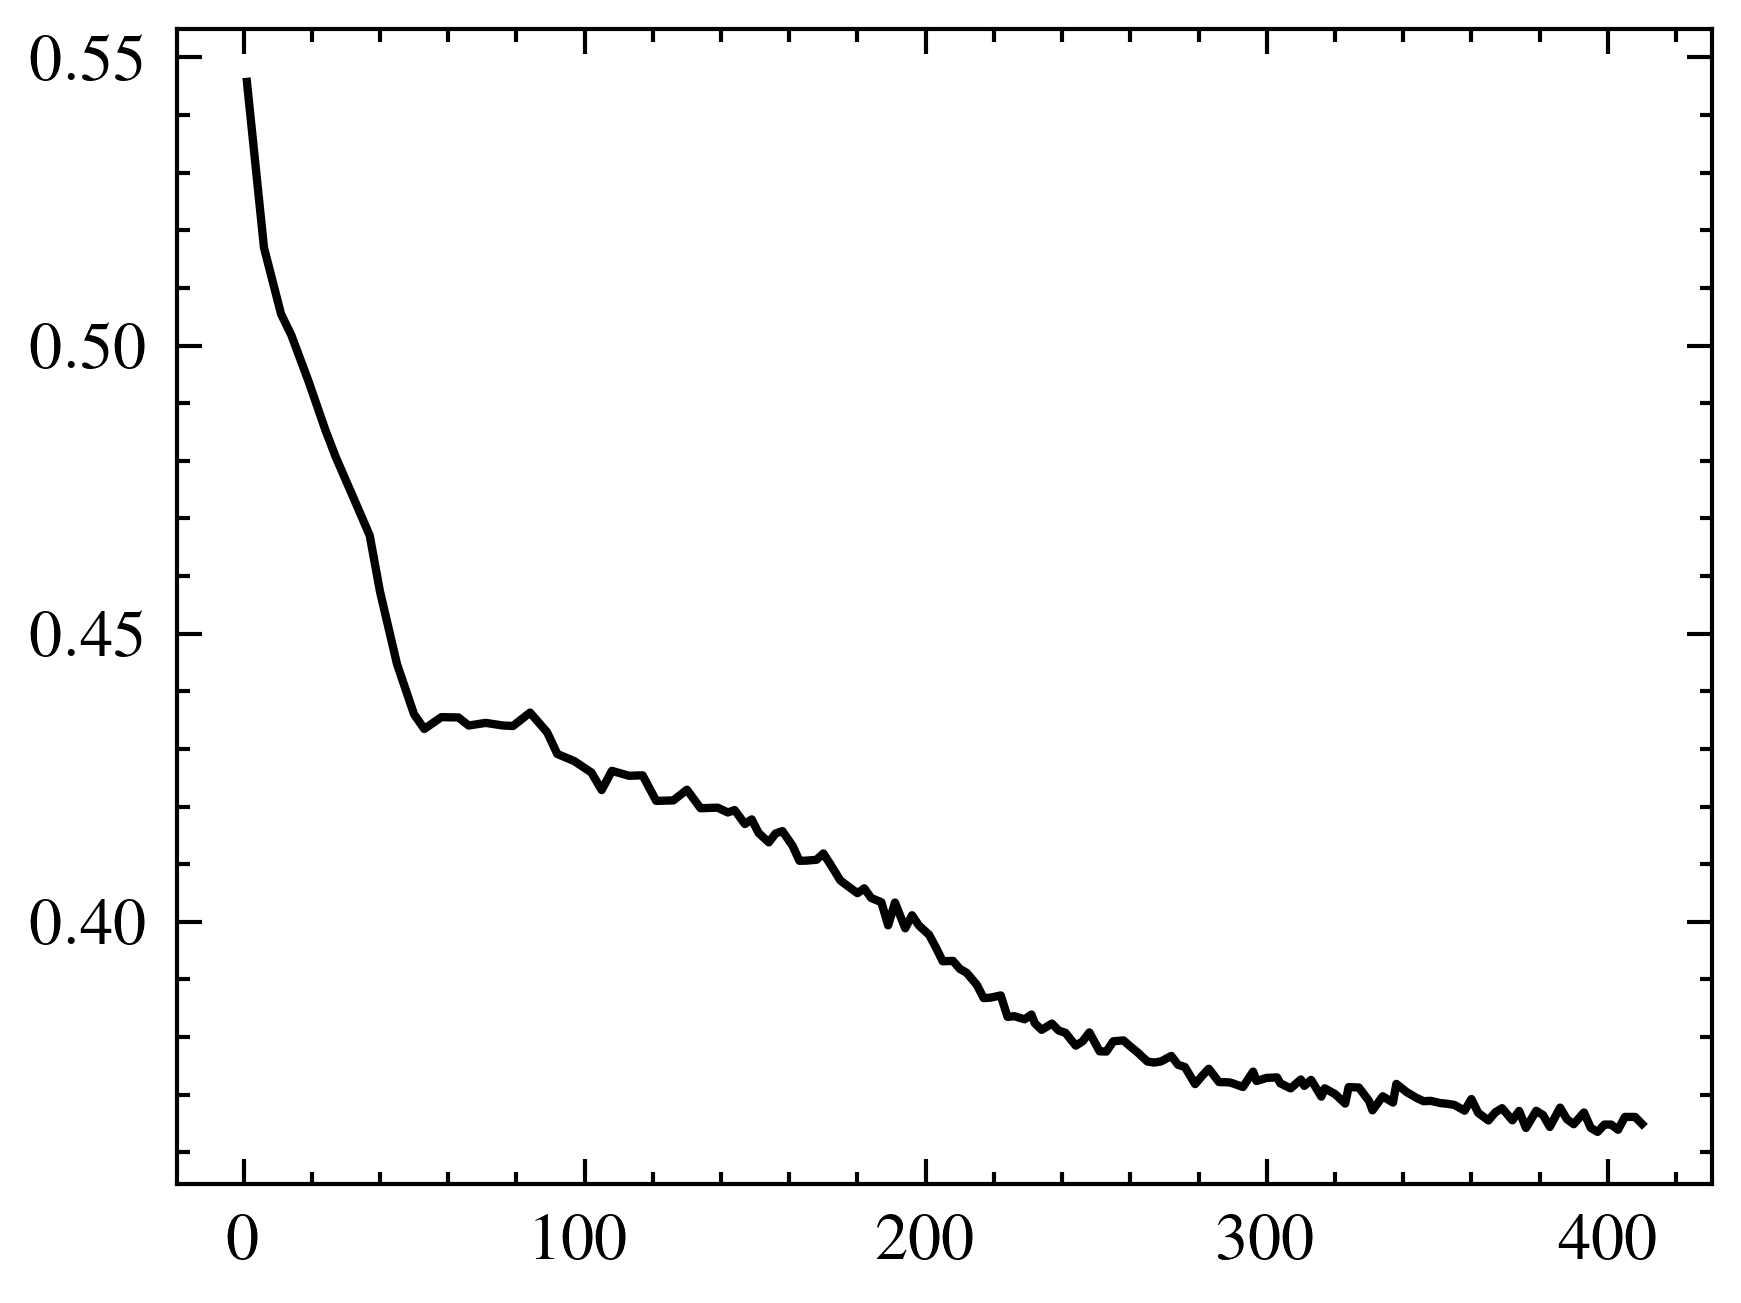

In [10]:
os.listdir()
intensity_train_csv = pd.read_csv(os.path.join("analysis", "intensity-train.csv"))

a = intensity_train_csv["events FIREnet baseline - train_loss_epoch"]
plt.plot(a[a.notna()])
plt.show()

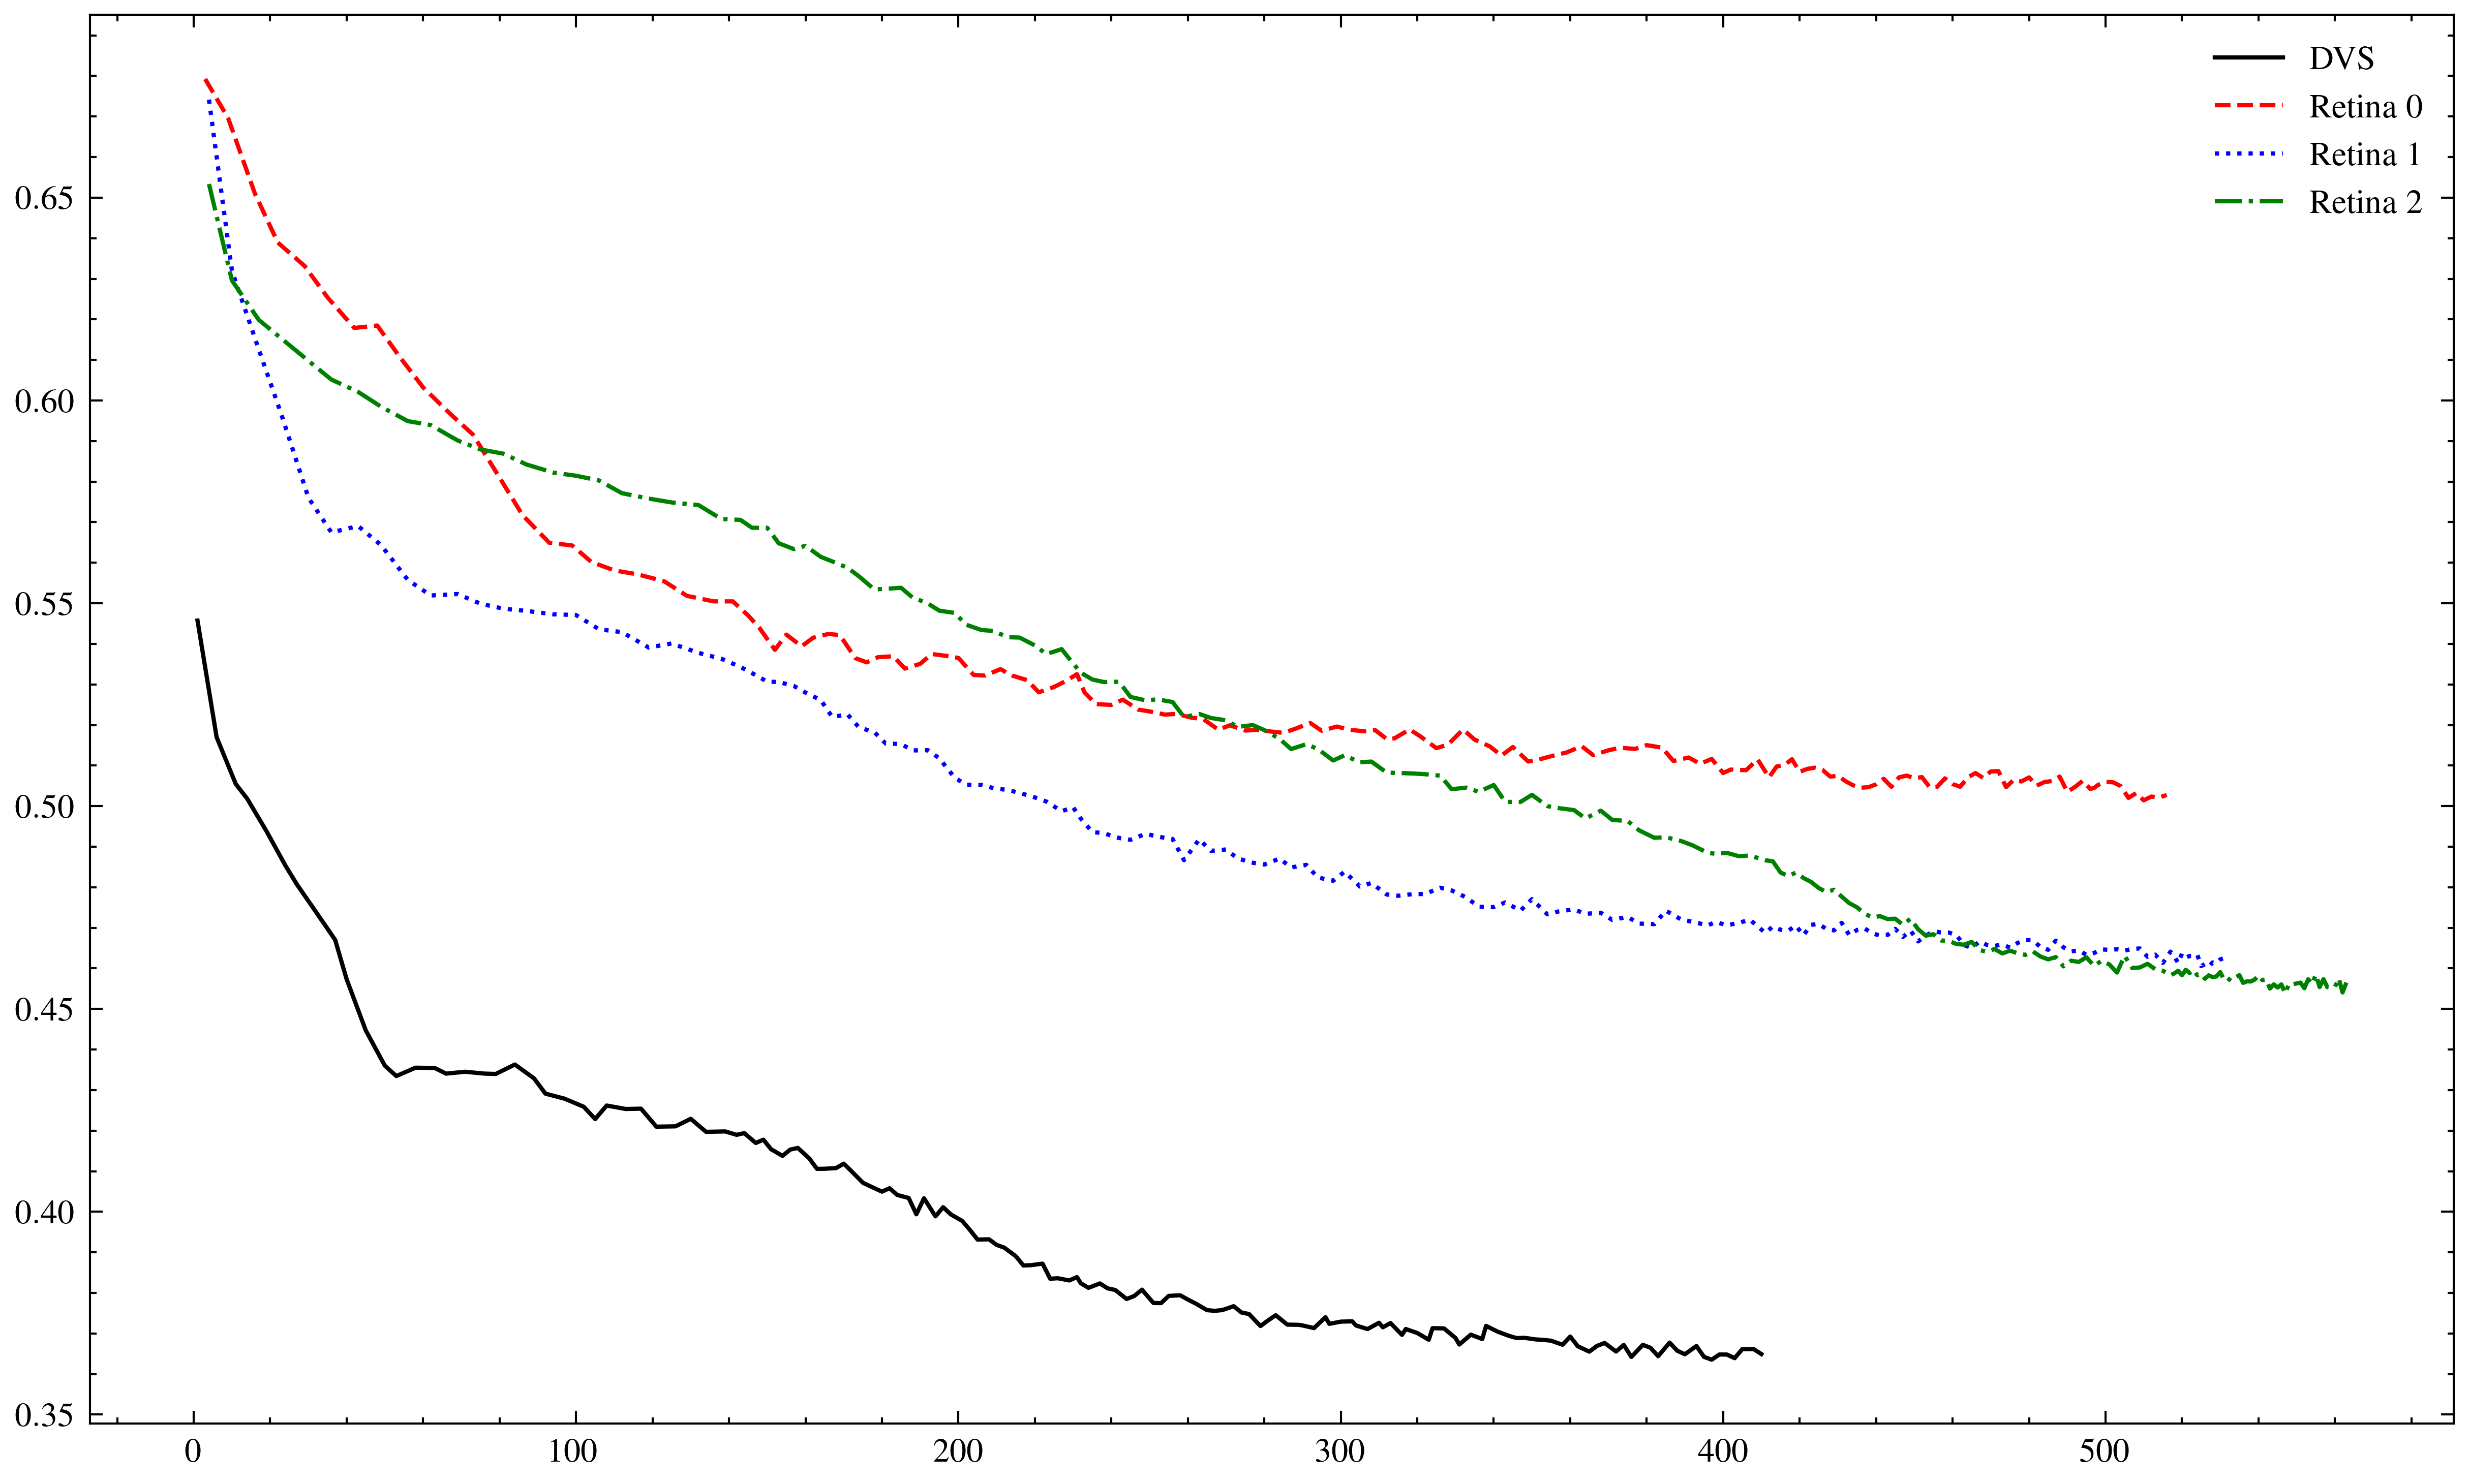

In [11]:
dvs_group_train = ['events FIREnet baseline - train_loss_epoch']

retina_group_train = ['retina : burnin = 20, seq = 40 - train_loss_epoch',
                'retina : burn in = 10 ,seq = 30 - train_loss_epoch',
                'retina : seq = 20 - train_loss_epoch']


plt.figure(figsize=(10, 6))

for col in dvs_group_train:
    data = intensity_train_csv[col]
    plt.plot(data[data.notna()], label="DVS")

for i, col in enumerate(retina_group_train):
    data = intensity_train_csv[col]
    plt.plot(data[data.notna()], label=f"Retina {i}")

plt.legend()
plt.show()

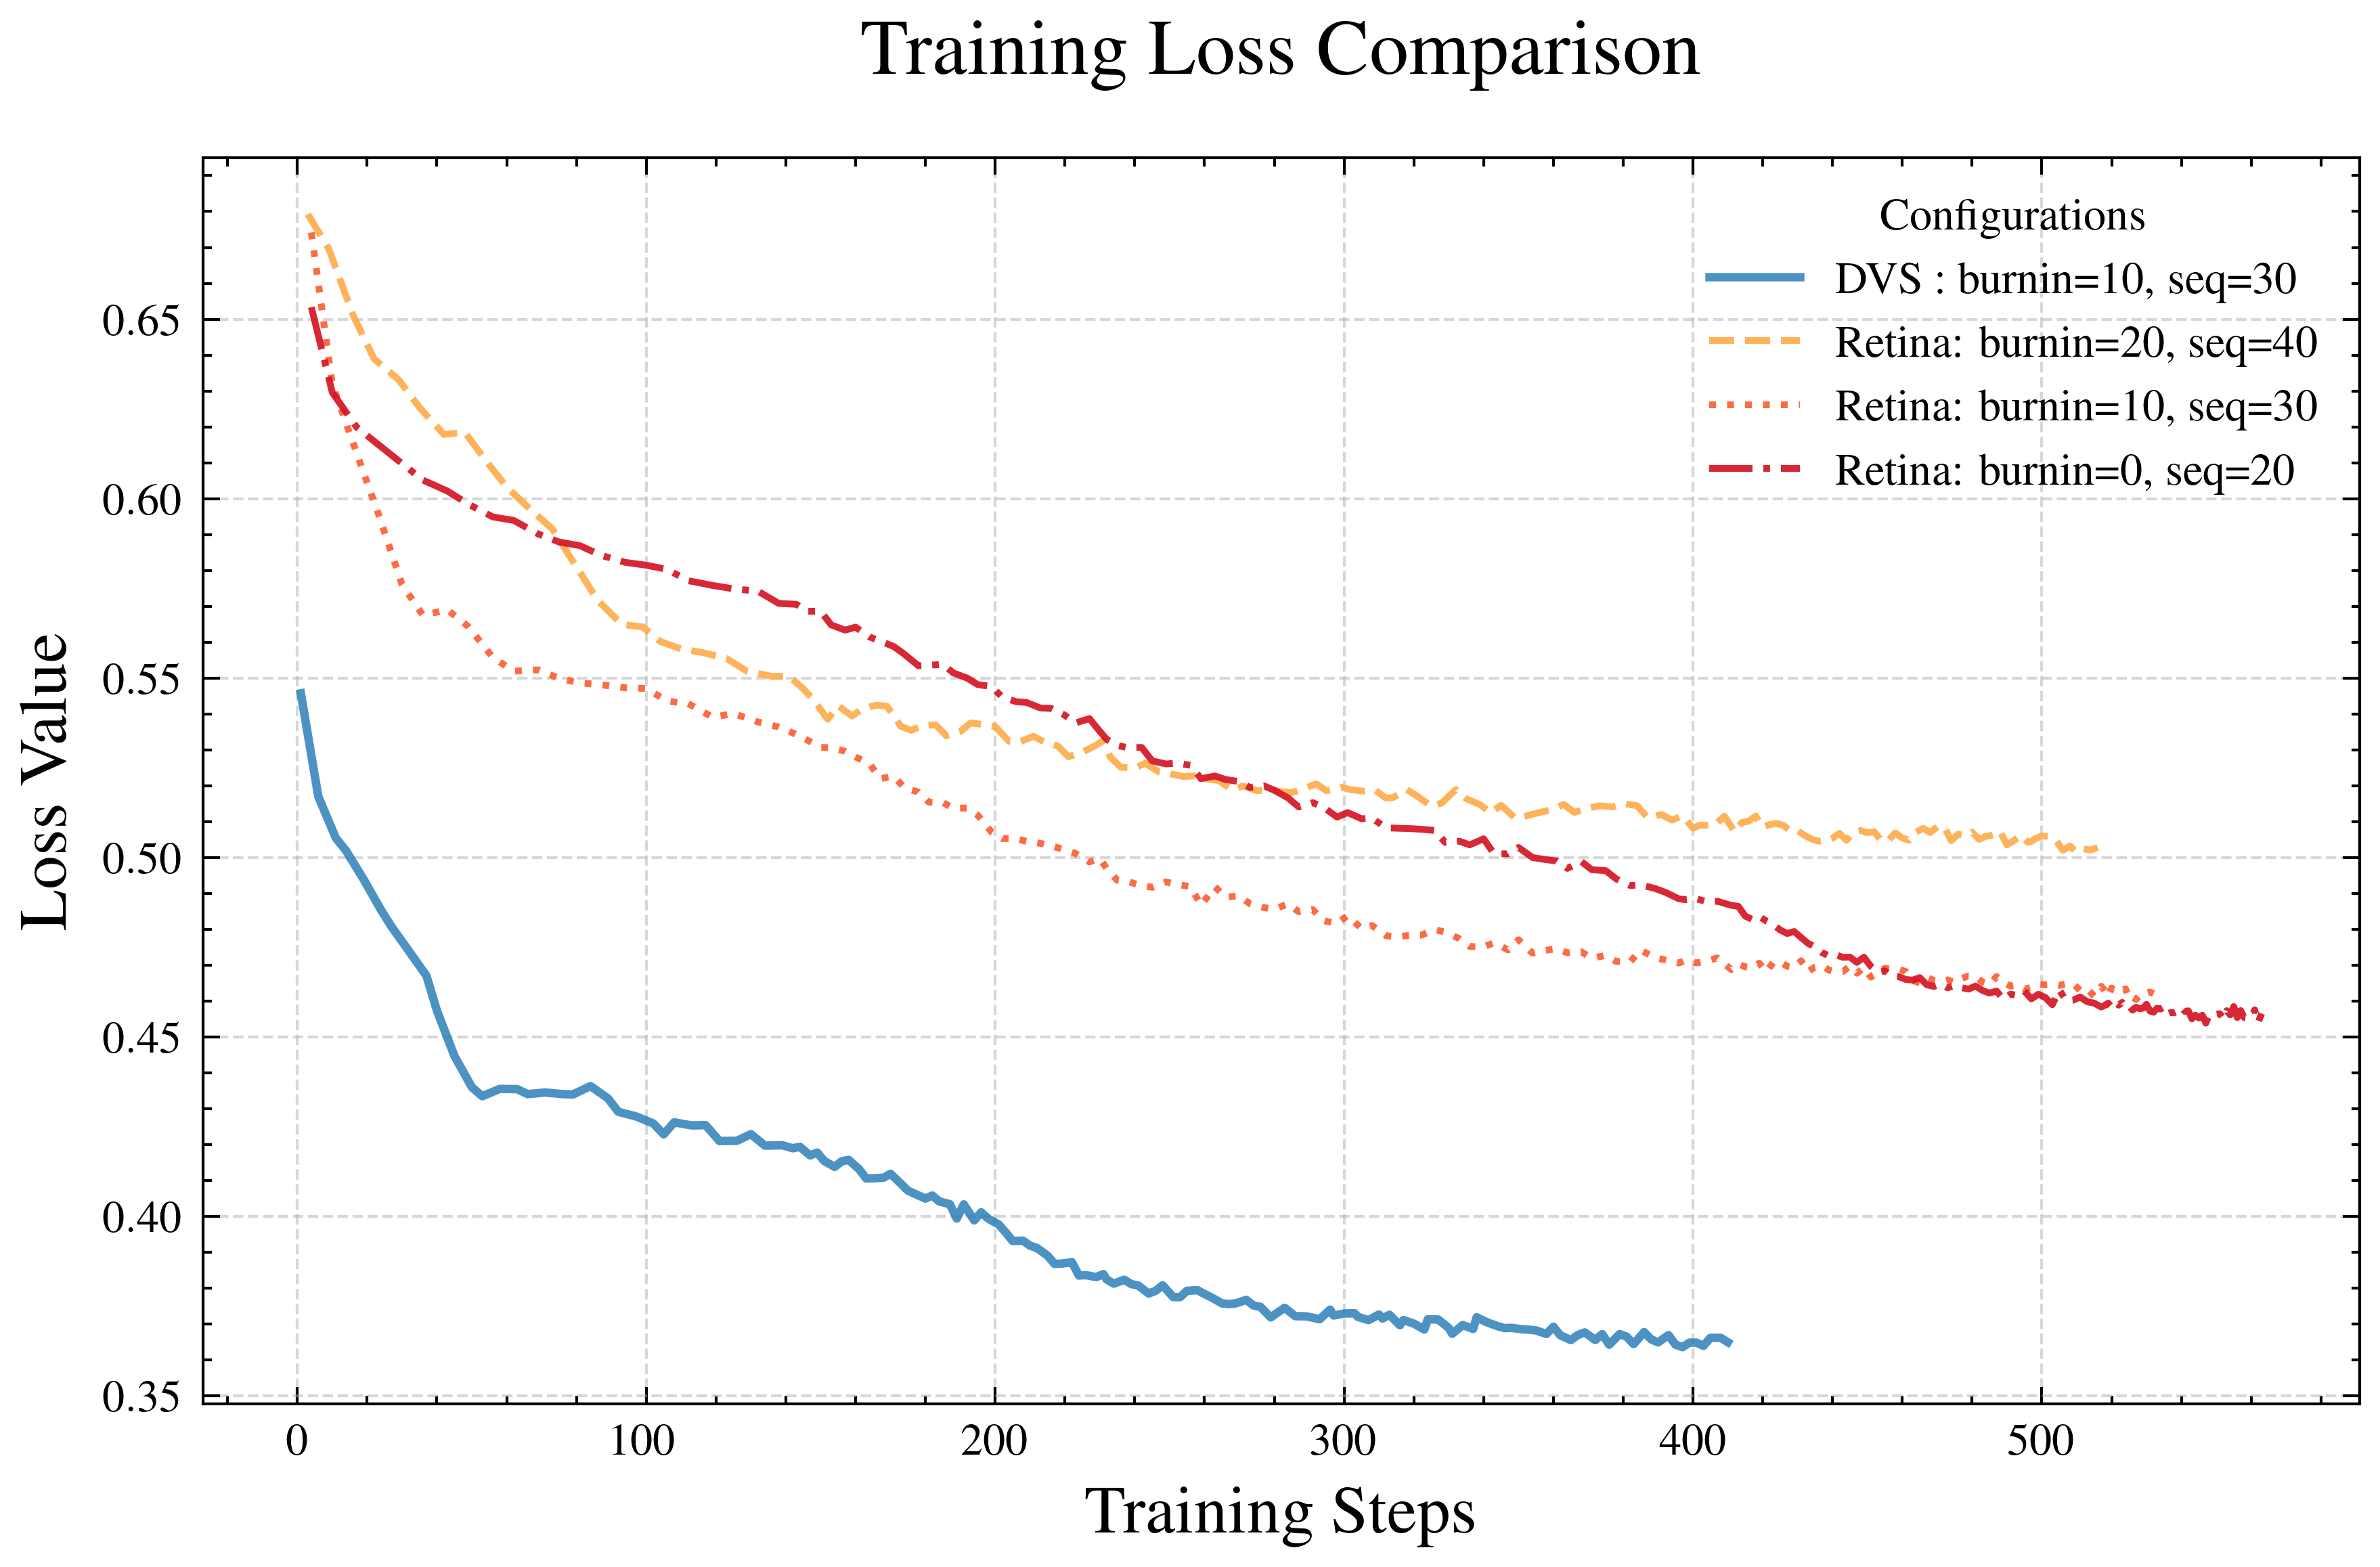

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.style.use(['science', 'ieee']) 

dvs_label_names = ["burnin=10, seq=30"]
retina_label_names = ["burnin=20, seq=40",
                      "burnin=10, seq=30",
                      "burnin=0, seq=20"]

def plot_loss_data(df, dvs_group, dvs_label_names,
                   retina_group, retina_label_names, is_train, smoothing=0.0):
    fig, ax = plt.subplots(figsize=(6, 4))
    
    prefix = "Training" if is_train else "Validation"
        
    
    dvs_color = '#1f77b4' 
    for col in dvs_group:
        data = df[col].dropna()
        
        if smoothing > 0:
            smoothed = data.ewm(alpha=1-smoothing).mean()
            ax.plot(data.index, smoothed, label=f"DVS : {dvs_label_names[0]}", 
                    color=dvs_color, linewidth=2, alpha=1.0)
            # Optional: Plot raw data faintly in background
            ax.plot(data.index, data, color=dvs_color, linewidth=1, alpha=0.2)
        else:
            ax.plot(data.index, data, label=f"DVS : {dvs_label_names[0]}", 
                    color=dvs_color, linewidth=1.5, alpha=0.8)

    # 2. Plot Retina Group (Using a gradient of similar colors)
    # Using 'Oranges' or 'autumn' colormap to get distinct but related shades
    retina_colors = plt.cm.YlOrRd(np.linspace(0.4, 0.8, len(retina_group)))

    for i, col in enumerate(retina_group):
        data = df[col].dropna()
        
        # Clean label for the legend (removing the suffix)
        clean_label = col.split('-')[0].strip()
        
        if smoothing > 0:
            smoothed = data.ewm(alpha=1-smoothing).mean()
            ax.plot(data.index, smoothed, label=f"Retina: {retina_label_names[i]}", 
                    color=retina_colors[i], linewidth=1.8)
        else:
            ax.plot(data.index, data, label=f"Retina: {retina_label_names[i]}", 
                    color=retina_colors[i], linewidth=1.2, alpha=0.9)

    # 3. Polish the graph
    ax.set_xlabel(f'{prefix} Steps', fontsize=12)
    ax.set_ylabel(r'Loss Value', fontsize=12)
    ax.set_title(f'{prefix} Loss Comparison', fontsize=14, pad=15)
    
    # Legend placement: best usually works, but outside is safer for many lines
    ax.legend(title='Configurations', loc='upper right')
    
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    plt.savefig(f'intensity_{prefix.lower()}_loss.png', dpi=300, bbox_inches='tight')
    plt.show()

# Usage with your dataframe
plot_loss_data(intensity_train_csv, 
               dvs_group_train, dvs_label_names,
               retina_group_train, retina_label_names, is_train=True, smoothing=0.0)

In [13]:
print("intensity DVS train min :", np.min(intensity_train_csv[dvs_group_train]))
print("intensity retina train min :", np.min(intensity_train_csv[retina_group_train]))

intensity DVS train min : 0.3635396540227821
intensity retina train min : 0.4538548311268394


# Validation 

In [14]:
dvs_group_val = ['events FIREnet baseline - val_loss_epoch']

retina_group_val = ['retina : burnin = 20, seq = 40 - val_loss_epoch',
                    'retina : burn in = 10 ,seq = 30 - val_loss_epoch',
                    'retina : seq = 20 - val_loss_epoch']

os.listdir()
intensity_val_csv = pd.read_csv(os.path.join("analysis", "intensity-val.csv"))
print(intensity_val_csv.columns)

Index(['Step', 'FIREnetwork_20250902_015420 - val_loss_epoch',
       'FIREnetwork_20250902_015420 - val_loss_epoch__MIN',
       'FIREnetwork_20250902_015420 - val_loss_epoch__MAX',
       'events FIREnet baseline - val_loss_epoch',
       'events FIREnet baseline - val_loss_epoch__MIN',
       'events FIREnet baseline - val_loss_epoch__MAX',
       'retina, burnin=10, seq=30, Bins=5, OF video input - val_loss_epoch',
       'retina, burnin=10, seq=30, Bins=5, OF video input - val_loss_epoch__MIN',
       'retina, burnin=10, seq=30, Bins=5, OF video input - val_loss_epoch__MAX',
       'FIREnetwork_20250829_031148 - val_loss_epoch',
       'FIREnetwork_20250829_031148 - val_loss_epoch__MIN',
       'FIREnetwork_20250829_031148 - val_loss_epoch__MAX',
       'FIREnetwork_20250828_170108 - val_loss_epoch',
       'FIREnetwork_20250828_170108 - val_loss_epoch__MIN',
       'FIREnetwork_20250828_170108 - val_loss_epoch__MAX',
       'FIREnetwork_20250827_122510 - val_loss_epoch',
       '

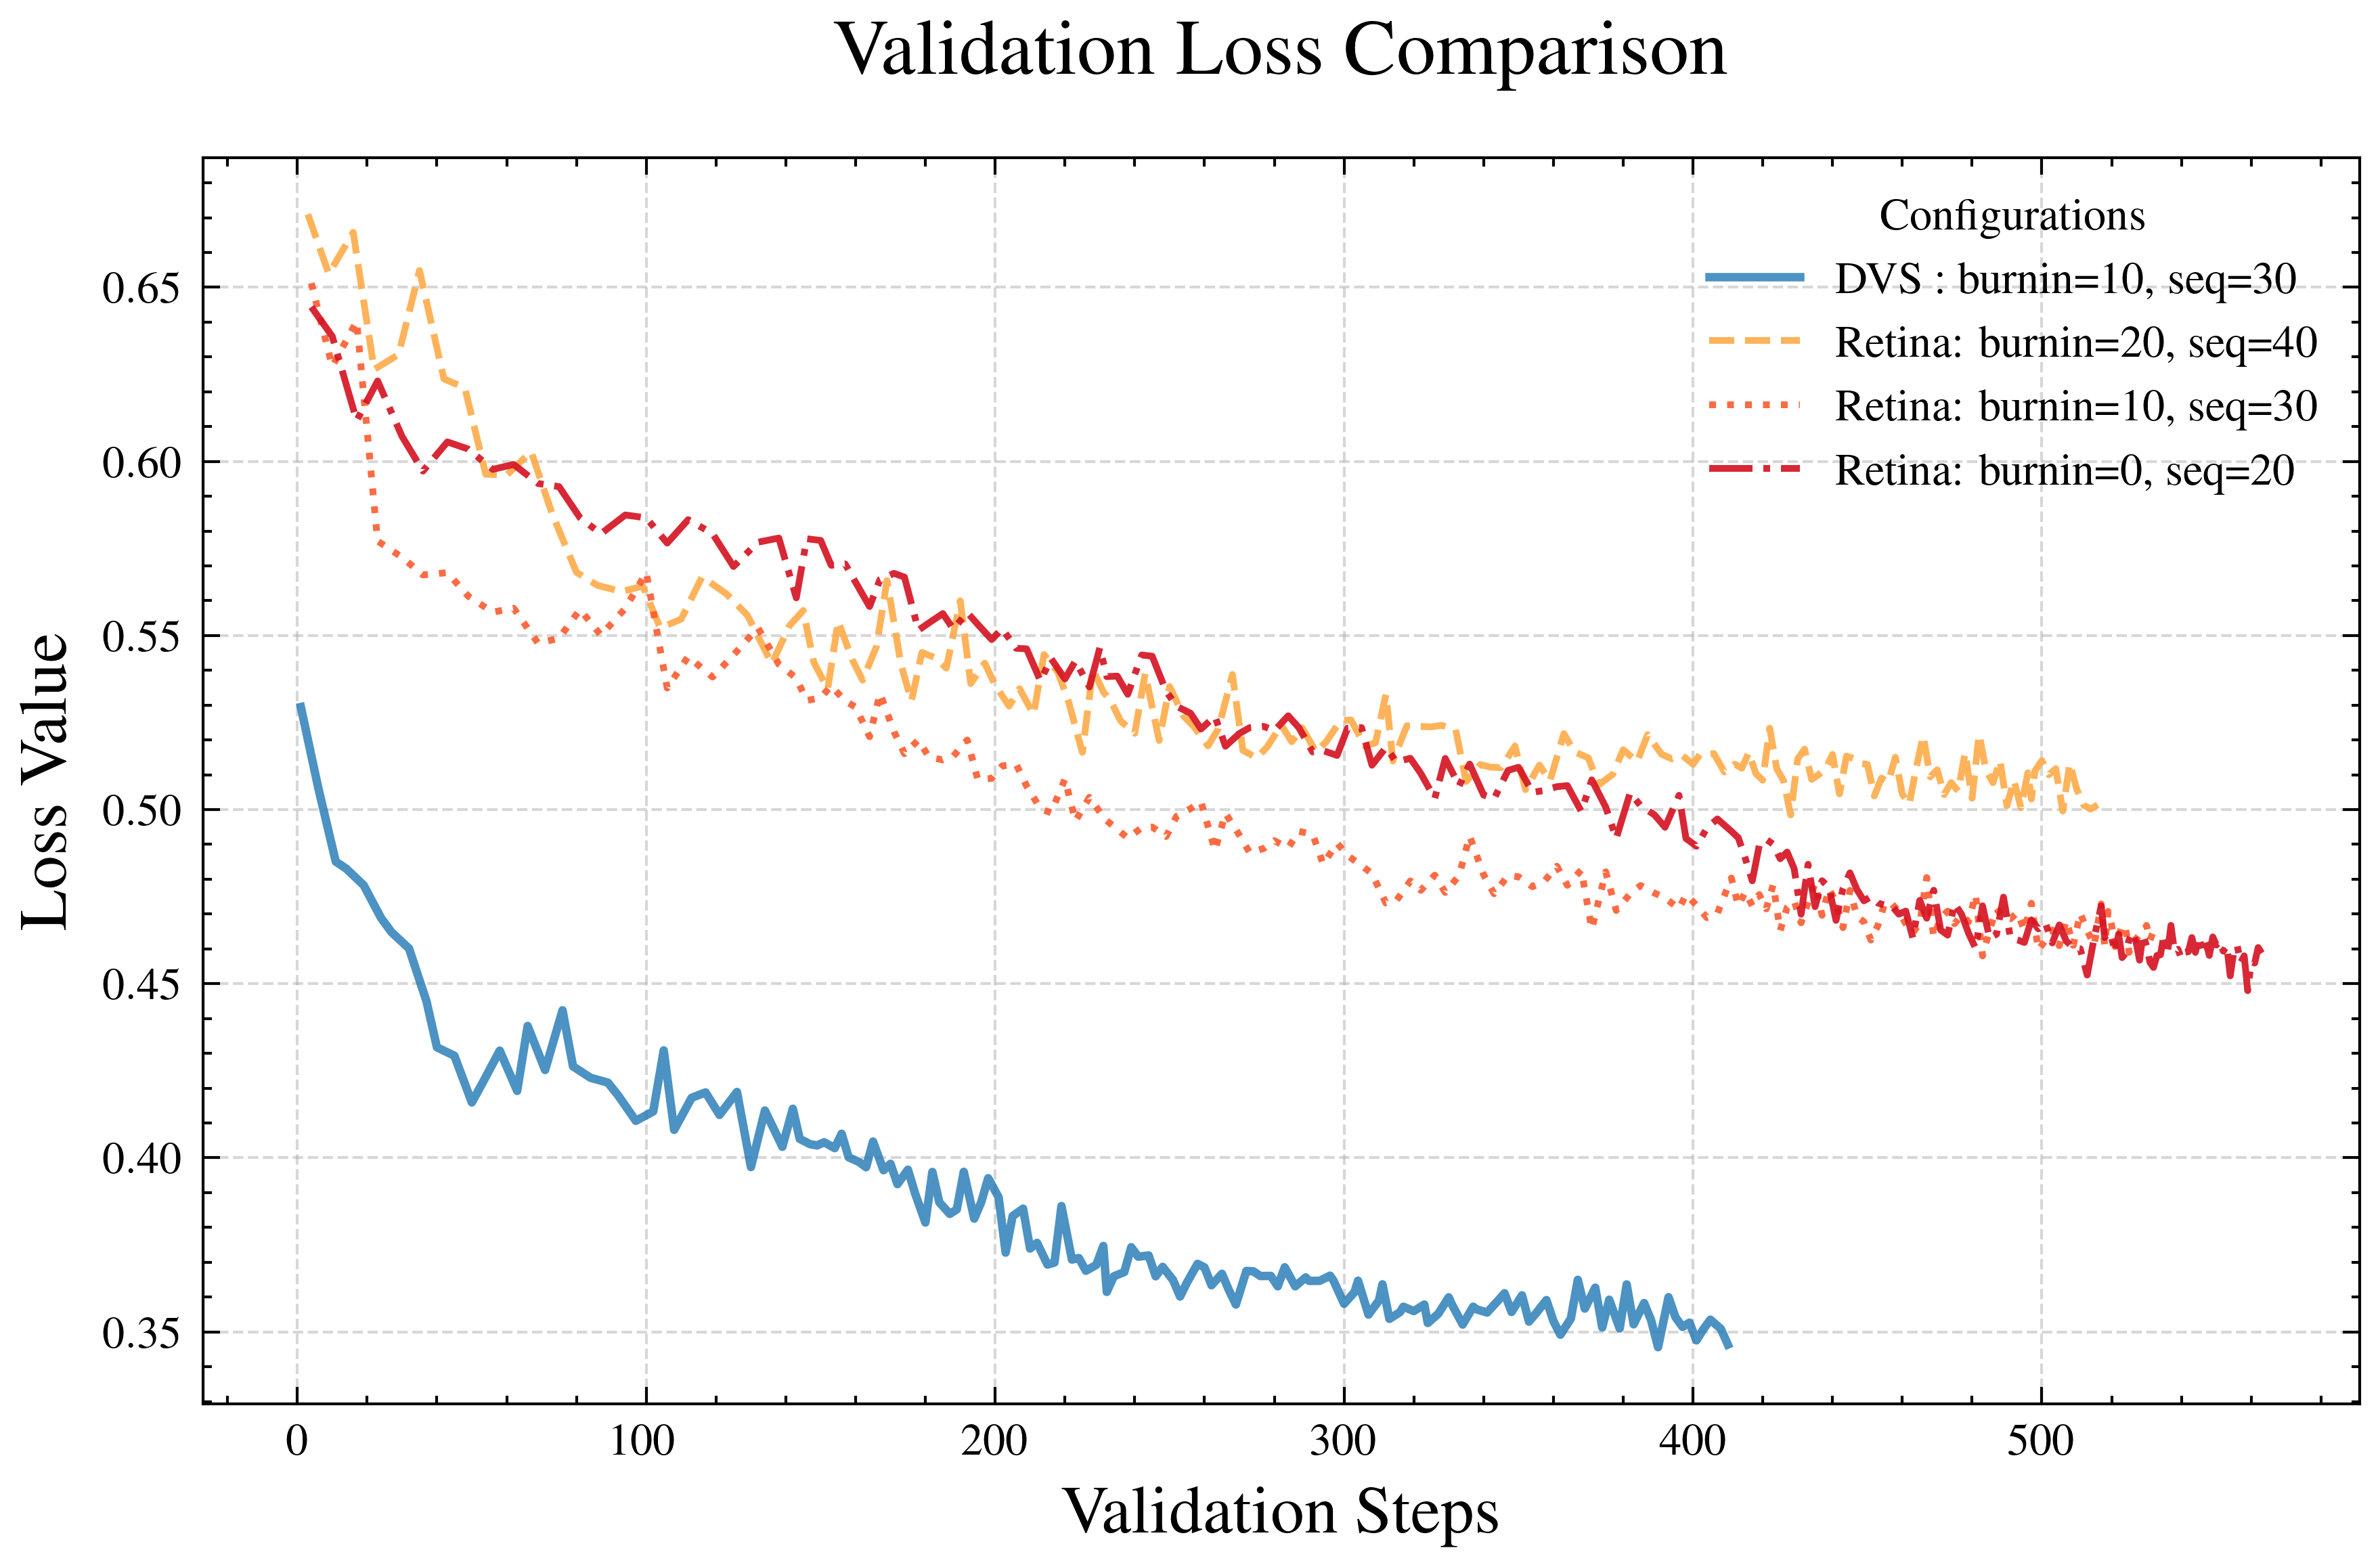

In [15]:
plot_loss_data(intensity_val_csv, 
               dvs_group_val, dvs_label_names,
               retina_group_val, retina_label_names, smoothing=0.0, is_train=False)

In [16]:
print("intensity DVS val min :", np.min(intensity_val_csv[dvs_group_val]))
print("intensity retina val min :", np.min(intensity_val_csv[retina_group_val]))

intensity DVS val min : 0.3456010692394696
intensity retina val min : 0.4479986170404835
